In [2]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
from Minimal_Model_2D import *
import Minimal_model_1D_1sub as M_1sub
import Minimal_Model_1D as M1
import time

np.set_printoptions(threshold=sys.maxsize)

In [35]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(0, 31, 101)

K = 8

Ep_li_1d = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M1.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("1d_model_subbands_{}_linear_SpinSplitting_width_{}nm.npy".format(MY, LY), Ep_li_1d)


first subband energy = 2.3579449364034835 
 second subband energy = 4.715889872806967
first subband= 1.1789724682017417 second subband = 3.536917404605225
MU = 1.9789724682017418
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


In [103]:
NSM = 60          # in nm
MY = 5             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(0, 31, 101)

K = 8

Ep_li_1deff = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

#### Anomaly at alpha=48

for i in range(ALPHAT.shape[0]):

    Fli = M_1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SM, MU_SM, phi=PHI)
    
    Hli = Fli.H_sys()

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1deff[i,:] = Eli

    if ALPHAT[i] > 45 and ALPHAT[i] < 52 :

        print(Eli, 'alpha =' ,ALPHAT[i], 'spin_splitting:', Eli[K//2+1]-Eli[K//2]) 
    
    if i%5==0:
        print(i)


np.save("1deff_model_linear_SpinSplitting_width_{}nm.npy".format( LY), Ep_li_1deff)

first subband energy = 2.3579449364034835 
 second subband energy = 4.715889872806967
first subband= 1.1789724682017417 second subband = 3.536917404605225
MU = 1.9789724682017418
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


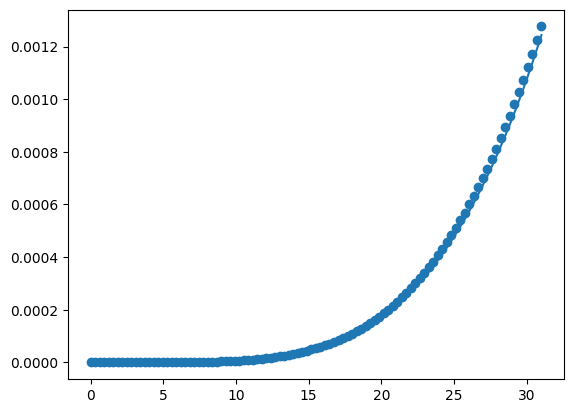

In [36]:
plt.plot(ALPHAT, Ep_li_1d[:,K//2+1]-Ep_li_1d[:,K//2])
plt.scatter(ALPHAT, Ep_li_1deff[:,K//2+1]-Ep_li_1deff[:,K//2])

In [29]:
NSM = 60          # in nm
#MY = 5             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

M = 75
AY= 5 

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(0, 31, 101)

K = 8

Ep_li_2d = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    ModCT = twoD_Minimal_Model(N, NSM, NSC, M, AX, AY, OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

    H = ModCT.H_sys(PHI, 'li')

    E = eigsh(H, k=K, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep_li_2d[i,:] = Es

    #print(Es)

    #print(H.shape)

    if i % 5 == 0 :

        print(i)


np.save("2d_model_linear_SpinSplitting_width_{}nm.npy".format(LY), Ep_li_2d)

first subband energy = 2.3579449364034835 
 second subband energy = 4.715889872806967
first subband= 1.1789724682017417 second subband = 3.536917404605225
MU = 1.9789724682017418
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


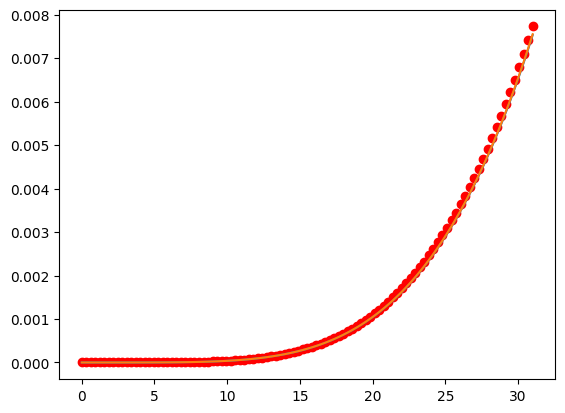

In [44]:
plt.plot(ALPHAT, (Ep_li_1d[:,K//2+1]-Ep_li_1d[:,K//2])/DELTA)
plt.scatter(ALPHAT, (Ep_li_1deff[:,K//2+1]-Ep_li_1deff[:,K//2])/DELTA, color='red')
plt.plot(ALPHAT, (Ep_li_2d[:,K//2+1]-Ep_li_2d[:,K//2])/DELTA)
#plt.ylim(ymin=0, ymax=0.0002)

In [45]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(0, 1000, 101)

K = 8

Ep_cu_1d = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fcu = M1.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)

np.save("1d_model_subbands_{}_cubic_SpinSplitting_width_{}nm.npy".format(MY, LY), Ep_cu_1d)


first subband energy = 2.3579449364034835 
 second subband energy = 4.715889872806967
first subband= 1.1789724682017417 second subband = 3.536917404605225
MU = 1.9789724682017418
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


In [50]:
MY=7
Ep_cu_1d = np.load("1d_model_subbands_{}_cubic_SpinSplitting_width_{}nm.npy".format(MY, LY))

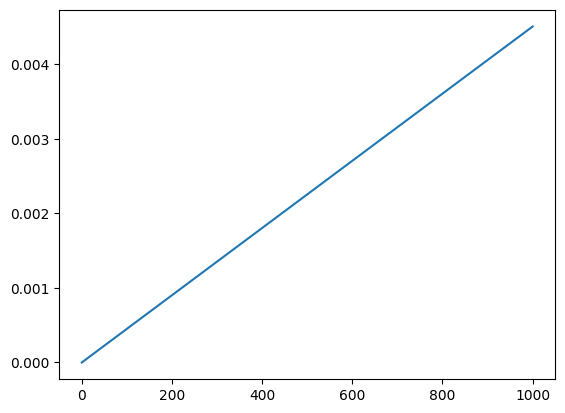

In [51]:
plt.plot(ALPHAT, (Ep_cu_1d[:,K//2+1]-Ep_cu_1d[:,K//2])/DELTA)

In [49]:
NSM = 60          # in nm
MY = 1             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(0, 1000, 101)

K = 8

Ep_cu_1d_eff = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fcu = M1.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d_eff[i,:] = Ecu
    
    if i%5==0:
        print(i)

np.save("1d_eff_model_subbands_{}_cubic_SpinSplitting_width_{}nm.npy".format(MY, LY), Ep_cu_1d_eff)


first subband energy = 2.3579449364034835 
 second subband energy = 4.715889872806967
first subband= 1.1789724682017417 second subband = 3.536917404605225
MU = 1.9789724682017418
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


In [2]:
NSM = 60          # in nm
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

M = 75
AY= 5 

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(0, 1000, 101)

K = 8

Ep_cu_2d = np.empty((ALPHAT.shape[0],K))

for i in range(ALPHAT.shape[0]):

    ModCT = twoD_Minimal_Model(N, NSM, NSC, M, AX, AY, OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

    H = ModCT.H_sys(PHI, 'cu')

    E = eigsh(H, k=K, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep_cu_2d[i,:] = Es

    #print(Es)

    #print(H.shape)

    if i % 5 == 0 :

        print(i)


np.save("2d_model_cubic_SpinSplitting_width_{}nm.npy".format(LY), Ep_cu_2d)

first subband energy = 2.3579449364034835 
 second subband energy = 4.715889872806967
first subband= 1.1789724682017417 second subband = 3.536917404605225
MU = 1.9789724682017418
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80
85
90
95
100


In [3]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.8 + OMEGA/2   #in between two subbands
MU_SM =  0.8 + OMEGA/2   #in between two subbands

print("first subband=", OMEGA/2, "second subband =", 3*OMEGA/2)

print("MU =", MU_SC)

ALPHAT = np.linspace(0, 31, 101)

K = 8

first subband energy = 2.3579449364034835 
 second subband energy = 4.715889872806967
first subband= 1.1789724682017417 second subband = 3.536917404605225
MU = 1.9789724682017418


<>:42: SyntaxWarning: invalid escape sequence '\m'
<>:42: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Vivrekar\AppData\Local\Temp\3\ipykernel_26436\707592370.py:42: SyntaxWarning: invalid escape sequence '\m'
  '''


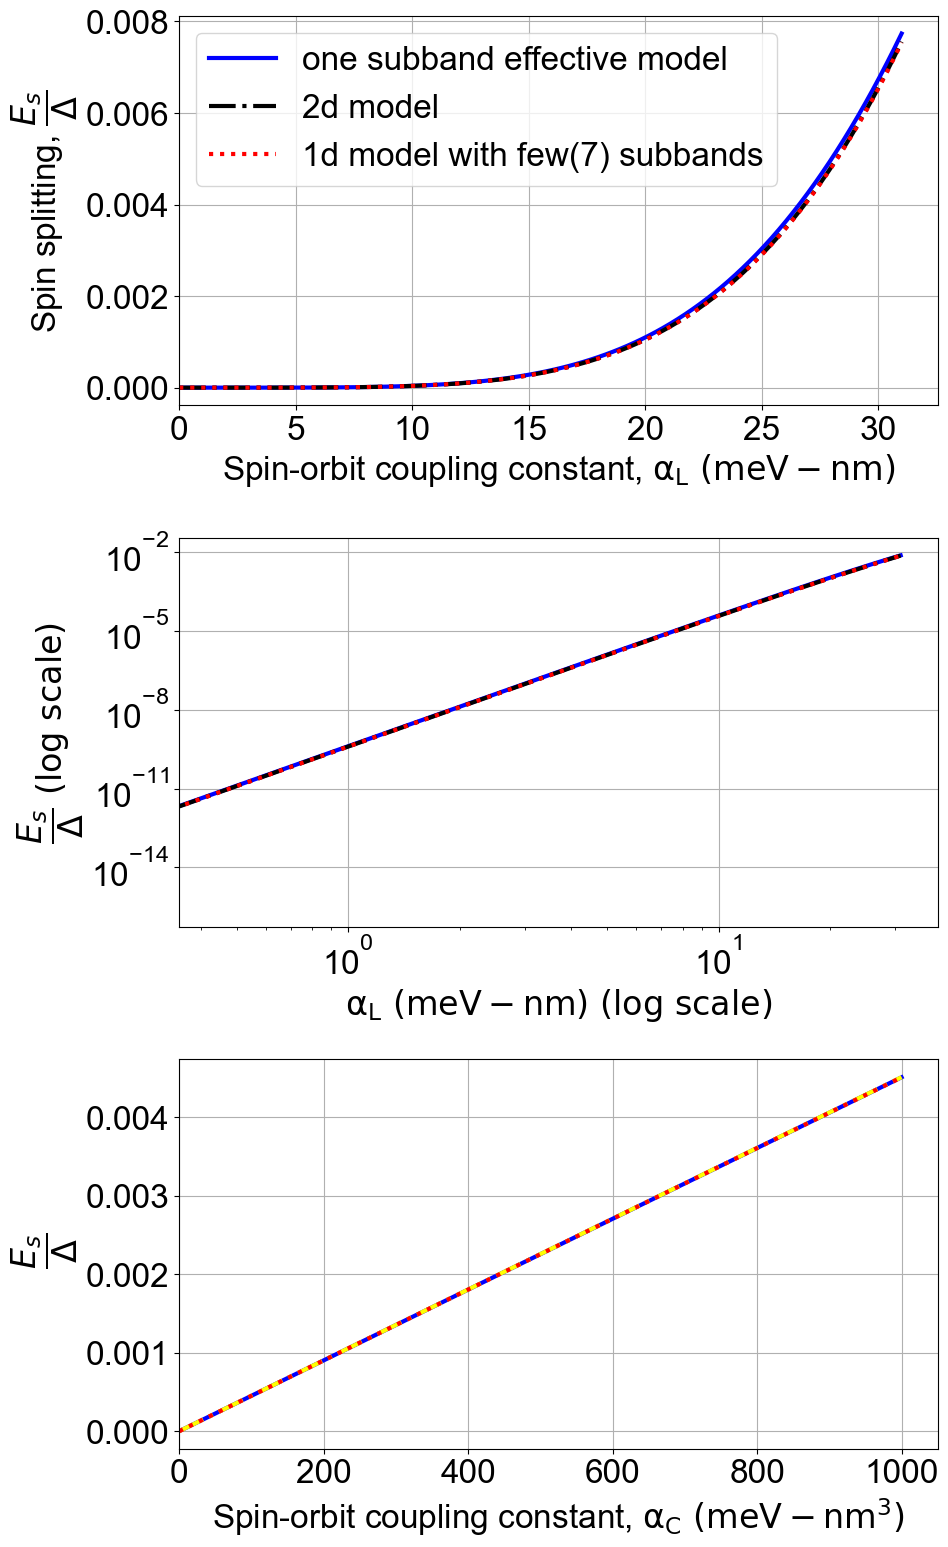

In [10]:
ALPHATL = np.linspace(0, 31, 101)
ALPHATC = np.linspace(0, 1000, 101)

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 16))


Ep_li_1d = np.load("1d_model_subbands_7_linear_SpinSplitting_width_75nm.npy")

Ep_li_1deff = np.load("1deff_model_linear_SpinSplitting_width_75nm.npy")

Ep_li_2d = np.load("2d_model_linear_SpinSplitting_width_5nm.npy")

Ep_cu_1d = np.load("1d_model_subbands_7_cubic_SpinSplitting_width_75nm.npy")

Ep_cu_1d_eff = np.load("1d_eff_model_subbands_1_cubic_SpinSplitting_width_75nm.npy")

Ep_cu_2d= np.load("2d_model_cubic_SpinSplitting_width_75nm.npy")

Ep_Split_li_1d = (Ep_li_1d[:,K//2+1] - Ep_li_1d[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])

Ep_Split_cu_1d = (Ep_cu_1d[:,K//2+1] - Ep_cu_1d[:,K//2])
Ep_Split_cu_1deff = (Ep_cu_1d_eff[:,K//2+1] - Ep_cu_1d_eff[:,K//2])
Ep_Split_cu_2d = (Ep_cu_2d[:,K//2+1] - Ep_cu_2d[:,K//2])

plt.subplot(3,1,1)
plt.plot((ALPHATL), (Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHATL), (Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label= '2d model')
plt.plot((ALPHATL), (Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label= '1d model with few(7) subbands')
plt.xlabel(r'Spin-orbit coupling constant, $\mathrm{\alpha_L} \ \mathrm{(meV-nm)}$')
plt.ylabel(r'Spin splitting, $\dfrac{E_{s}}{\mathrm{\Delta}}$')
plt.grid(True)
plt.xlim(left=0)
plt.legend()

'''
plt.subplot(3,1,2)
plt.plot((ALPHATL), (Ep_Split_li_1deff/DELTA)**(0.2), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHATL), (Ep_Split_li_2d/DELTA)**(0.2), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot((ALPHATL), (Ep_Split_li_1d/DELTA)**(0.2), lw=3 ,linestyle =':' , color='red', label='1d model with few(7) subbands')
plt.xlabel(r'Spin-orbit coupling constant, $\mathrm{\alpha_L} \ \mathrm{(meV-nm)} $', fontsize=24)
plt.ylabel(r'$\left(\dfrac{E_s}{\Delta}\right)^{1/5}$', fontsize=24)
plt.xlim(left=0)
plt.grid(True)
'''

plt.subplot(3,1,2)
plt.plot((ALPHATL), (Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHATL), (Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot((ALPHATL), (Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label='1d model with few(7) subbands')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\mathrm{\alpha_L} \ \mathrm{(meV-nm) \ (log \ scale)} $', fontsize=24)
plt.ylabel(r'$\dfrac{E_s}{\Delta} \ \mathrm{ (log \ scale)}$', fontsize=24)
plt.xlim(left=0.35)
plt.grid(True)


plt.subplot(3,1,3)
plt.plot((ALPHATC), (Ep_Split_cu_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHATC), (Ep_Split_cu_2d/DELTA), lw=3 ,linestyle ='-.' , color='YELLOW', label= '2d model')
plt.plot((ALPHATC), (Ep_Split_cu_1d/DELTA), lw=3 ,linestyle =':' , color='red', label= '1d model with few(7) subbands')
plt.xlabel(r'Spin-orbit coupling constant, $\mathrm{\alpha_C} \ \mathrm{(meV-nm^{3})}$')
plt.ylabel(r' $\dfrac{E_{s}}{\mathrm{\Delta}}$')
plt.grid(True)
plt.xlim(left=0)

#plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()



plt.show()

<Figure size 1000x1600 with 0 Axes>

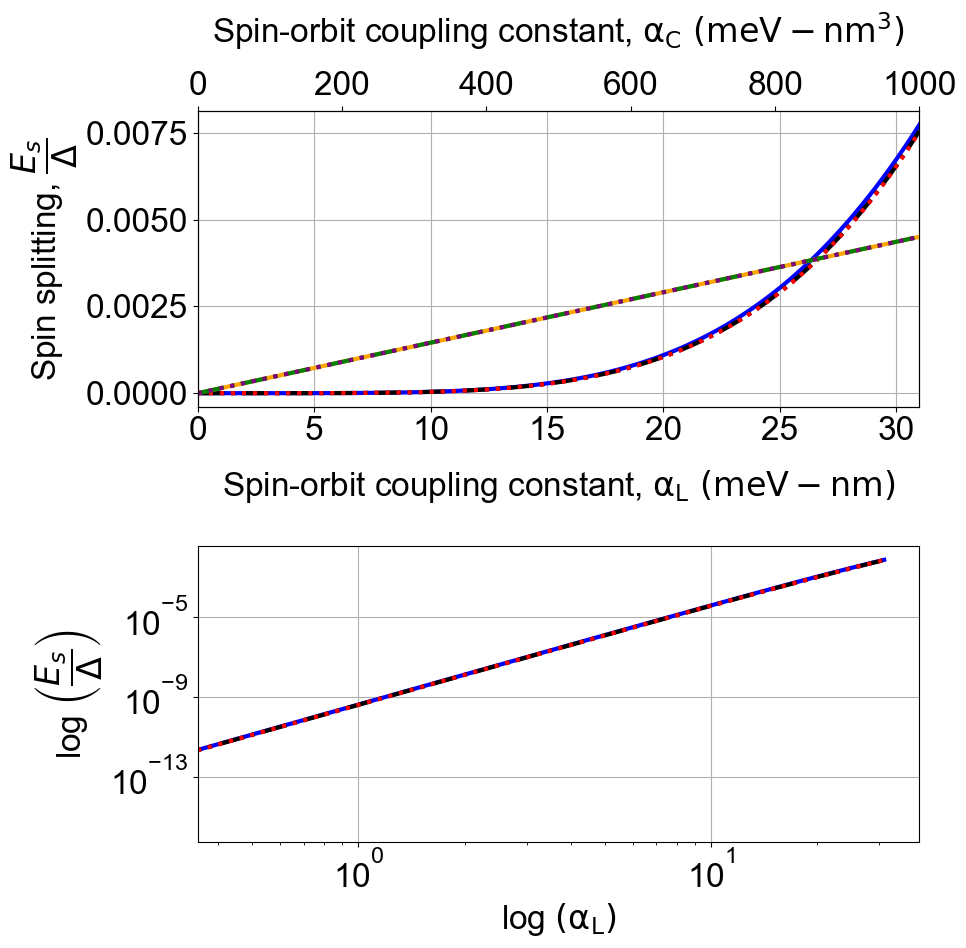

In [32]:

# Assuming the relevant numpy arrays (Ep_li_1d, Ep_li_1deff, etc.) are already loaded
ALPHATL = np.linspace(0, 31, 101)
ALPHATC = np.linspace(0, 1000, 101)

K=8

DELTA = 0.165      # in meV

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 16))



Ep_li_1d = np.load("1d_model_subbands_7_linear_SpinSplitting_width_75nm.npy")

Ep_li_1deff = np.load("1deff_model_linear_SpinSplitting_width_75nm.npy")

Ep_li_2d = np.load("2d_model_linear_SpinSplitting_width_5nm.npy")

Ep_cu_1d = np.load("1d_model_subbands_7_cubic_SpinSplitting_width_75nm.npy")

Ep_cu_1d_eff = np.load("1d_eff_model_subbands_1_cubic_SpinSplitting_width_75nm.npy")

Ep_cu_2d= np.load("2d_model_cubic_SpinSplitting_width_75nm.npy")

Ep_Split_li_1d = (Ep_li_1d[:,K//2+1] - Ep_li_1d[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])

Ep_Split_cu_1d = (Ep_cu_1d[:,K//2+1] - Ep_cu_1d[:,K//2])
Ep_Split_cu_1deff = (Ep_cu_1d_eff[:,K//2+1] - Ep_cu_1d_eff[:,K//2])
Ep_Split_cu_2d = (Ep_cu_2d[:,K//2+1] - Ep_cu_2d[:,K//2])

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=24)

f = plt.figure(figsize=(10, 10))

# Create the first subplot (linear spin-orbit coupling)
ax1 = plt.subplot(2, 1, 1)

# Plot for the primary x-axis (linear spin-orbit coupling constants)
ax1.plot((ALPHATL), (Ep_Split_li_1deff / DELTA), lw=3, linestyle='-', color='blue', label='one subband effective model (linear)')
ax1.plot((ALPHATL), (Ep_Split_li_2d / DELTA), lw=3, linestyle='-.', color='black', label='2d model (linear)')
ax1.plot((ALPHATL), (Ep_Split_li_1d / DELTA), lw=3, linestyle=':', color='red', label='1d model with few(7) subbands (linear)')

# Set labels, limits, and grid for primary x-axis
ax1.set_xlabel(r'Spin-orbit coupling constant, $\mathrm{\alpha_L} \ \mathrm{(meV-nm)}$', labelpad=15)
ax1.set_ylabel(r'Spin splitting, $\dfrac{E_s}{\mathrm{\Delta}}$')
ax1.set_xlim([0, 31])
ax1.grid(True)

# Create the secondary x-axis for cubic spin-orbit coupling
ax2 = ax1.twiny()

# Plot for the secondary x-axis (cubic spin-orbit coupling constants)
ax2.plot((ALPHATC), (Ep_Split_cu_1deff / DELTA), lw=3, linestyle='-', color='orange', label='one subband effective model (cubic)')
ax2.plot((ALPHATC), (Ep_Split_cu_2d / DELTA), lw=3, linestyle='-.', color='green', label='2d model (cubic)')
ax2.plot((ALPHATC), (Ep_Split_cu_1d / DELTA), lw=3, linestyle=':', color='purple', label='1d model with few(7) subbands (cubic)')

# Set labels, limits, and grid for secondary x-axis
ax2.set_xlabel(r'Spin-orbit coupling constant, $\mathrm{\alpha_C} \ \mathrm{(meV-nm^{3})}$', labelpad=20)
ax2.set_xlim([0, 1000])

# Combine legends from both axes
#lines_1, labels_1 = ax1.get_legend_handles_labels()
#lines_2, labels_2 = ax2.get_legend_handles_labels()
#ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

# Second plot (log-log scale plot)
plt.subplot(2, 1, 2)
plt.plot((ALPHATL), (Ep_Split_li_1deff / DELTA), lw=3, linestyle='-', color='blue', label='one subband effective model')
plt.plot((ALPHATL), (Ep_Split_li_2d / DELTA), lw=3, linestyle='-.', color='black', label='2d model')
plt.plot((ALPHATL), (Ep_Split_li_1d / DELTA), lw=3, linestyle=':', color='red', label='1d model with few(7) subbands')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'log $ \left( \mathrm{\alpha_L} \right)  $')
plt.ylabel(r'log $ \left( \dfrac{E_s}{\Delta} \right) $')
plt.xlim(left=0.35)
plt.grid(True)

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the plot
plt.show()

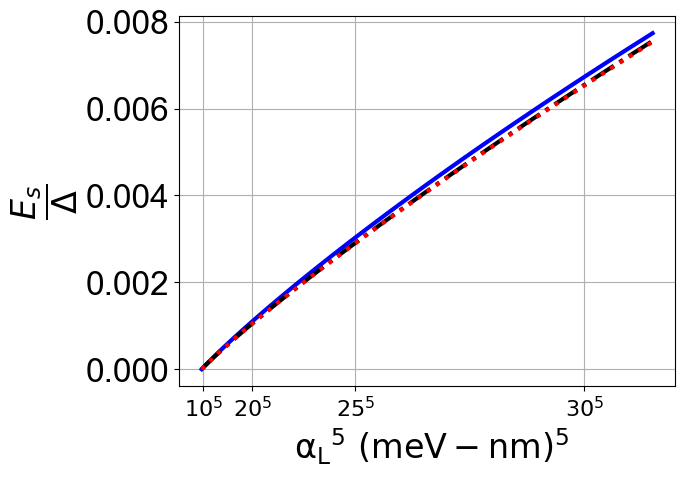

In [93]:
#plt.subplot(3,1,2)
plt.plot((ALPHATL)**5, (Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHATL)**5, (Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot((ALPHATL)**5, (Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label='1d model with few(7) subbands')
plt.xlabel(r' $\mathrm{\alpha_L}^5 \ \mathrm{(meV-nm)^5} $', fontsize=24)
plt.ylabel(r'$\dfrac{E_s}{\Delta}$', fontsize=24)
#plt.xscale('log')
X_TICKS = np.array([  10, 20, 25, 30])
# Manually set the x-axis ticks and labels
plt.xticks(X_TICKS**5, [f'${{{round(a)}}}^5$' for a in X_TICKS],fontsize=16)
#plt.xlim(left=0)
plt.grid(True)

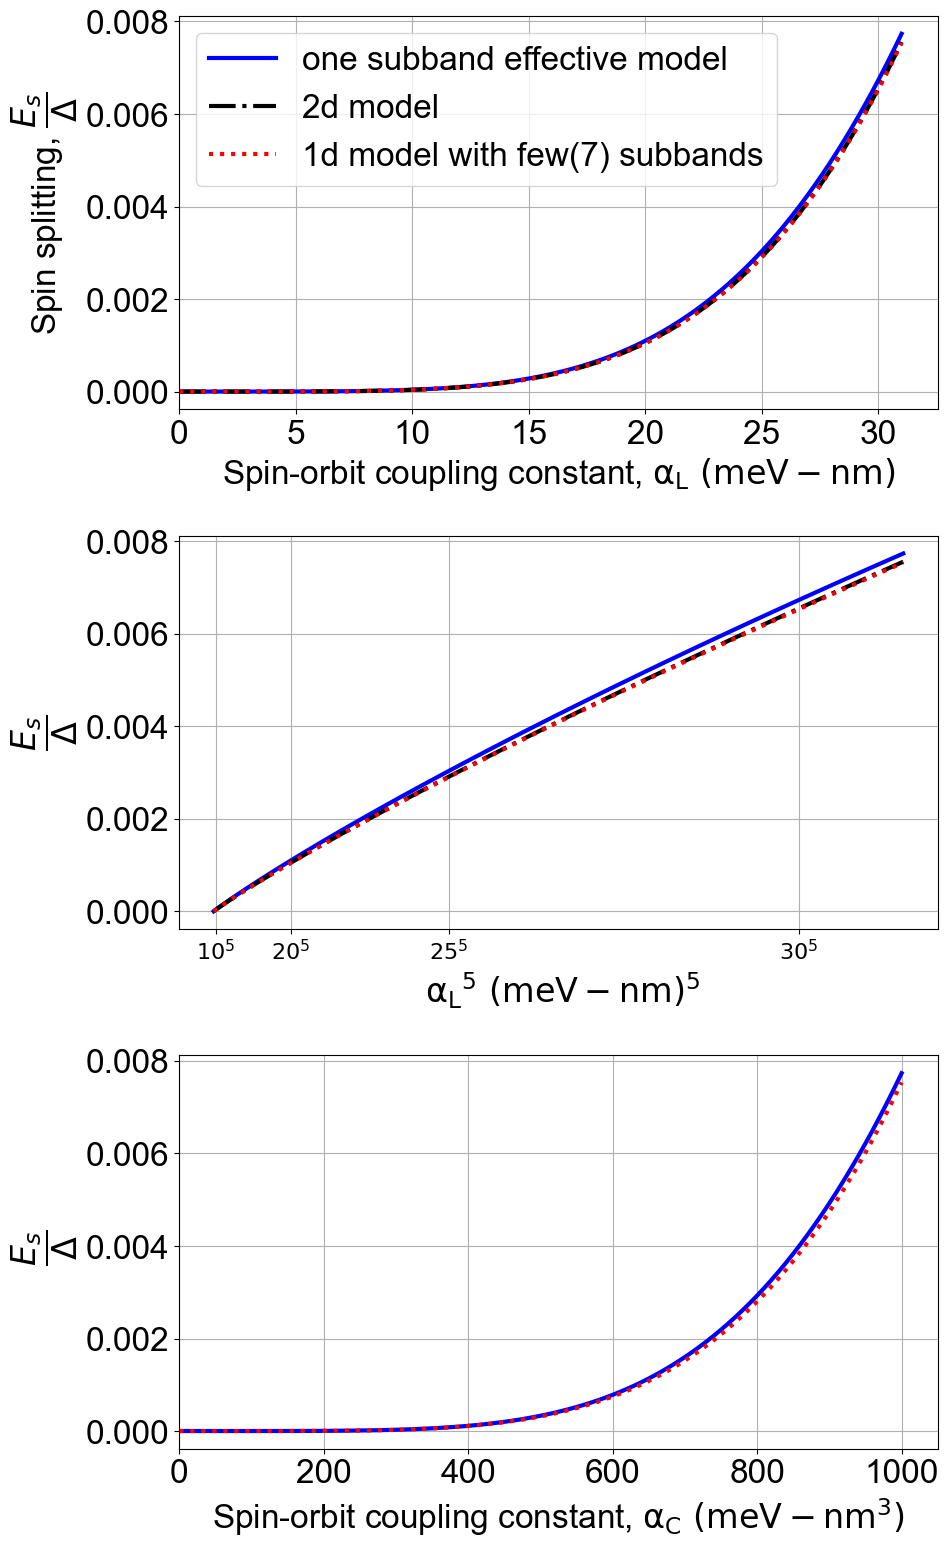

In [94]:
ALPHATL = np.linspace(0, 31, 101)
ALPHATC = np.linspace(0, 1000, 101)

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 16))

Ep_Split_li_1d = (Ep_li_1d[:,K//2+1] - Ep_li_1d[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])

Ep_Split_cu_1d = (Ep_li_1d[:,K//2+1] - Ep_li_1d[:,K//2])
Ep_Split_cu_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
#Ep_Split_cu_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])

plt.subplot(3,1,1)
plt.plot((ALPHATL), (Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHATL), (Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label= '2d model')
plt.plot((ALPHATL), (Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label= '1d model with few(7) subbands')
plt.xlabel(r'Spin-orbit coupling constant, $\mathrm{\alpha_L} \ \mathrm{(meV-nm)}$')
plt.ylabel(r'Spin splitting, $\dfrac{E_{s}}{\mathrm{\Delta}}$')
plt.grid(True)
plt.xlim(left=0)
plt.legend()

plt.subplot(3,1,2)
plt.plot((ALPHATL)**5, (Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHATL)**5, (Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot((ALPHATL)**5, (Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label='1d model with few(7) subbands')
plt.xlabel(r' $\mathrm{\alpha_L}^5 \ \mathrm{(meV-nm)^5} $', fontsize=24)
plt.ylabel(r'$\dfrac{E_s}{\Delta}$', fontsize=24)
#plt.xscale('log')
X_TICKS = np.array([  10, 20, 25, 30])
# Manually set the x-axis ticks and labels
plt.xticks(X_TICKS**5, [f'${{{round(a)}}}^5$' for a in X_TICKS],fontsize=16)
#plt.xlim(left=0)
plt.grid(True)

plt.subplot(3,1,3)
plt.plot((ALPHATC), (Ep_Split_cu_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
#plt.plot((ALPHATC), (Ep_Split_cu_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label= '2d model')
plt.plot((ALPHATC), (Ep_Split_cu_1d/DELTA), lw=3 ,linestyle =':' , color='red', label= '1d model with few(7) subbands')
plt.xlabel(r'Spin-orbit coupling constant, $\mathrm{\alpha_C} \ \mathrm{(meV-nm^{3})}$')
plt.ylabel(r' $\dfrac{E_{s}}{\mathrm{\Delta}}$')
plt.grid(True)
plt.xlim(left=0)

#plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()



plt.show()

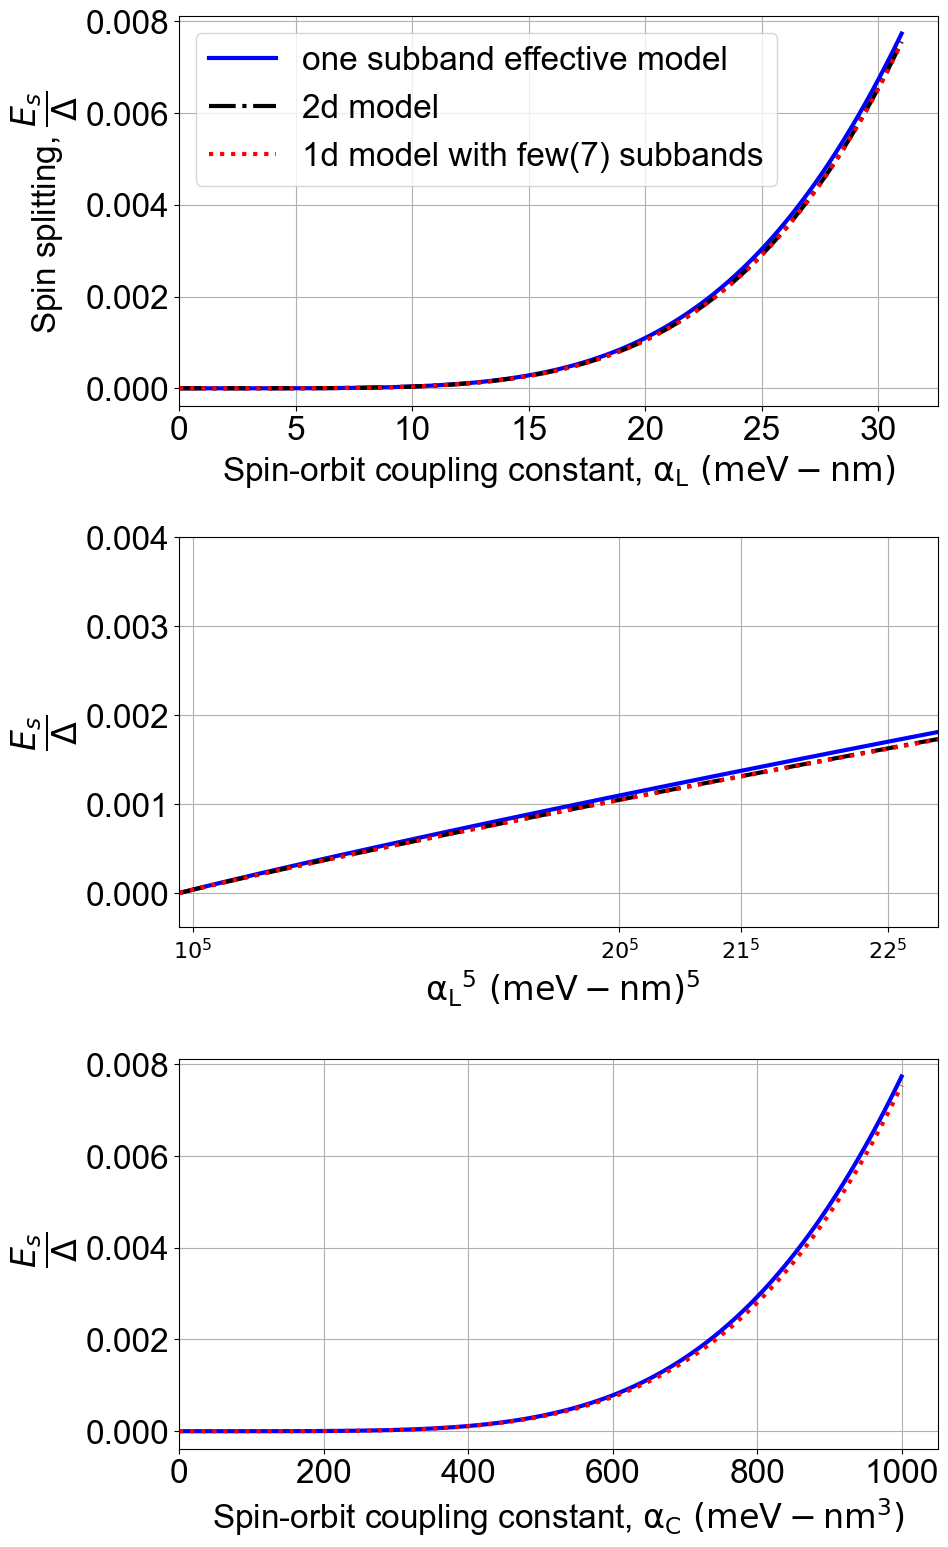

In [101]:
ALPHATL = np.linspace(0, 31, 101)
ALPHATC = np.linspace(0, 1000, 101)

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 16))

Ep_Split_li_1d = (Ep_li_1d[:,K//2+1] - Ep_li_1d[:,K//2])
Ep_Split_li_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
Ep_Split_li_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])

Ep_Split_cu_1d = (Ep_li_1d[:,K//2+1] - Ep_li_1d[:,K//2])
Ep_Split_cu_1deff = (Ep_li_1deff[:,K//2+1] - Ep_li_1deff[:,K//2])
#Ep_Split_cu_2d = (Ep_li_2d[:,K//2+1] - Ep_li_2d[:,K//2])

plt.subplot(3,1,1)
plt.plot((ALPHATL), (Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHATL), (Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label= '2d model')
plt.plot((ALPHATL), (Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label= '1d model with few(7) subbands')
plt.xlabel(r'Spin-orbit coupling constant, $\mathrm{\alpha_L} \ \mathrm{(meV-nm)}$')
plt.ylabel(r'Spin splitting, $\dfrac{E_{s}}{\mathrm{\Delta}}$')
plt.grid(True)
plt.xlim(left=0)
plt.legend()

plt.subplot(3,1,2)
plt.plot((ALPHATL)**5, (Ep_Split_li_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
plt.plot((ALPHATL)**5, (Ep_Split_li_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label=  '2d model')
plt.plot((ALPHATL)**5, (Ep_Split_li_1d/DELTA), lw=3 ,linestyle =':' , color='red', label='1d model with few(7) subbands')
plt.xlabel(r' $\mathrm{\alpha_L}^5 \ \mathrm{(meV-nm)^5} $', fontsize=24)
plt.ylabel(r'$\dfrac{E_s}{\Delta}$', fontsize=24)
#plt.xscale('log')
X_TICKS = np.array([  10, 20, 21, 22, 25, 30])
# Manually set the x-axis ticks and labels
plt.xticks(X_TICKS**5, [f'${{{round(a)}}}^5$' for a in X_TICKS],fontsize=16)
plt.xlim(right=22.3**5, left=0)
plt.ylim(ymax= 0.004)
plt.grid(True)

plt.subplot(3,1,3)
plt.plot((ALPHATC), (Ep_Split_cu_1deff/DELTA), lw=3 ,linestyle ='-' , color='blue', label= 'one subband effective model')
#plt.plot((ALPHATC), (Ep_Split_cu_2d/DELTA), lw=3 ,linestyle ='-.' , color='black', label= '2d model')
plt.plot((ALPHATC), (Ep_Split_cu_1d/DELTA), lw=3 ,linestyle =':' , color='red', label= '1d model with few(7) subbands')
plt.xlabel(r'Spin-orbit coupling constant, $\mathrm{\alpha_C} \ \mathrm{(meV-nm^{3})}$')
plt.ylabel(r' $\dfrac{E_{s}}{\mathrm{\Delta}}$')
plt.grid(True)
plt.xlim(left=0)

#plt.suptitle('Channel width = %i nm' %LY)

plt.tight_layout()



plt.show()